In [1]:
import pandas as pd
import numpy as np

musteri_sayisi = 200

data = {
    "CustomerId": range(1, musteri_sayisi + 1),
    "Age": np.random.randint(18, 70, musteri_sayisi),
    "Gender": np.random.choice(["Female", "Male"], musteri_sayisi),
    "MonthlyIncome": np.random.randint(5000, 40000, musteri_sayisi), # Aylık gelir (TL)
    "ShoppingFrequency": np.random.randint(1, 15, musteri_sayisi), # Aylık alışveriş sıklığı
    "AverageBasket": np.round(np.random.uniform(50.0, 3500.0, musteri_sayisi), 2), # Ortalama sepet tutarı
    "MembershipYears": np.random.randint(1, 11, musteri_sayisi),
    "DiscountUsage": np.random.choice(["Yes", "No"], musteri_sayisi)
}

df = pd.DataFrame(data)

In [2]:
df.head()

,CustomerId,Age,Gender,MonthlyIncome,ShoppingFrequency,AverageBasket,MembershipYears,DiscountUsage
0,1,35,Male,19323,11,2875.21,10,No
1,2,22,Male,14696,6,243.50,7,No
2,3,61,Male,21524,4,1665.62,3,No
3,4,24,Female,13821,14,2942.22,1,No
4,5,68,Female,15024,8,219.41,7,Yes


In [5]:
ortalama_yas = df["Age"].mean()
ortalama_gelir = df["MonthlyIncome"].mean()
ortalama_sepet = df["AverageBasket"].mean()
en_yuksek_sepet = df["AverageBasket"].max()
en_sik_musteriler = df.sort_values(by="ShoppingFrequency", ascending=False).head()

print(f"Ortalama Müşteri Yaşı: {ortalama_yas:.0f}")
print(f"Ortalama Gelir: {ortalama_gelir:.2f} TL")
print(f"Ortalama Sepet Tutarı: {ortalama_sepet:.2f} TL")
print(f"En Yüksek Sepet Tutarı: {en_yuksek_sepet} TL\n")
print("En Sık Alışveriş Yapan Müşteriler:\n", en_sik_musteriler[["CustomerId", "ShoppingFrequency"]])

Ortalama Müşteri Yaşı: 46
Ortalama Gelir: 21469.74 TL
Ortalama Sepet Tutarı: 1822.40 TL
En Yüksek Sepet Tutarı: 3478.99 TL

En Sık Alışveriş Yapan Müşteriler:
     CustomerId  ShoppingFrequency
3            4                 14
24          25                 14
32          33                 14
58          59                 14
64          65                 14


In [6]:
def segment_belirle(harcama):
    if harcama <= 500:
        return "Düşük"
    elif harcama <= 1500:
        return "Orta"
    elif harcama <= 3000:
        return "Yüksek"
    else:
        return "Çok Yüksek"
    
df['CustomerSegment'] = df['AverageBasket'].apply(segment_belirle)

print(df[['CustomerId', 'AverageBasket', 'CustomerSegment']].head(10))

   CustomerId  AverageBasket CustomerSegment
0           1        2875.21          Yüksek
1           2         243.50           Düşük
2           3        1665.62          Yüksek
3           4        2942.22          Yüksek
4           5         219.41           Düşük
5           6        1140.21            Orta
6           7        2324.61          Yüksek
7           8        1585.07          Yüksek
8           9         814.93            Orta
9          10        2288.31          Yüksek


In [7]:
df['MonthlySpending'] = df['ShoppingFrequency'] * df['AverageBasket']
df['IncomeSpendingRatio'] = df['MonthlySpending'] / df['MonthlyIncome']

print(df[['ShoppingFrequency', 'AverageBasket', 'MonthlySpending', 'MonthlyIncome', 'IncomeSpendingRatio']].head())

   ShoppingFrequency  AverageBasket  MonthlySpending  MonthlyIncome  \
0                 11        2875.21         31627.31          19323   
1                  6         243.50          1461.00          14696   
2                  4        1665.62          6662.48          21524   
3                 14        2942.22         41191.08          13821   
4                  8         219.41          1755.28          15024   

   IncomeSpendingRatio  
0             1.636770  
1             0.099415  
2             0.309537  
3             2.980326  
4             0.116832  


In [8]:
yas_harcama = df.groupby('Age')['MonthlySpending'].mean().sort_values(ascending=False)
print("Yaşlara Göre Ortalama Aylık Harcama (İlk 5 Yaş):\n", yas_harcama.head(), "\n")

cinsiyet_sepet = df.groupby('Gender')['AverageBasket'].mean()
print("Cinsiyete Göre Ortalama Sepet Tutarı:\n", cinsiyet_sepet, "\n")

uyelik_harcama = df.groupby('MembershipYears')['MonthlySpending'].mean().sort_index()
print("Üyelik Süresine Göre Ortalama Harcama:\n", uyelik_harcama, "\n")

indirim_siklik = df.groupby('DiscountUsage')['ShoppingFrequency'].mean()
print("İndirim Kullanımına Göre Alışveriş Sıklığı:\n", indirim_siklik)

Yaşlara Göre Ortalama Aylık Harcama (İlk 5 Yaş):
 Age
18    24830.580
36    24674.335
63    23919.740
27    23147.015
29    21561.300
Name: MonthlySpending, dtype: float64 

Cinsiyete Göre Ortalama Sepet Tutarı:
 Gender
Female    1804.906635
Male      1841.357083
Name: AverageBasket, dtype: float64 

Üyelik Süresine Göre Ortalama Harcama:
 MembershipYears
1     10242.599545
2     14252.351250
3      9213.254231
4     17478.026842
5     14918.091818
6     11562.176842
7     14134.237273
8     13928.675000
9     13530.711364
10    13852.960625
Name: MonthlySpending, dtype: float64 

İndirim Kullanımına Göre Alışveriş Sıklığı:
 DiscountUsage
No     7.406250
Yes    6.740385
Name: ShoppingFrequency, dtype: float64


In [9]:
df['Gender'] = df['Gender'].map({'Female': 0, 'Male': 1})
print(df[['CustomerId', 'Age', 'Gender']].head())

   CustomerId  Age  Gender
0           1   35       1
1           2   22       1
2           3   61       1
3           4   24       0
4           5   68       0


In [13]:
df['CustomerSegment'] = df['CustomerSegment'].map({
    "Düşük": 0,
    "Orta": 1,
    "Yüksek": 2,
    "Çok Yüksek": 3
})
print(df[['CustomerId', 'AverageBasket', 'CustomerSegment']].head())

   CustomerId  AverageBasket  CustomerSegment
0           1        2875.21                2
1           2         243.50                0
2           3        1665.62                2
3           4        2942.22                2
4           5         219.41                0


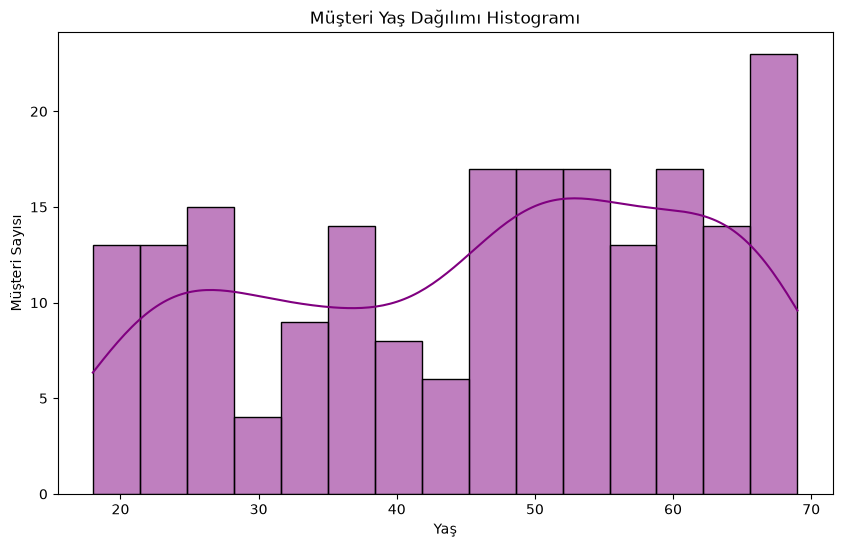

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(data=df, x='Age', bins=15, kde=True, color='purple')

plt.title("Müşteri Yaş Dağılımı Histogramı")
plt.xlabel("Yaş")
plt.ylabel("Müşteri Sayısı")

plt.show()

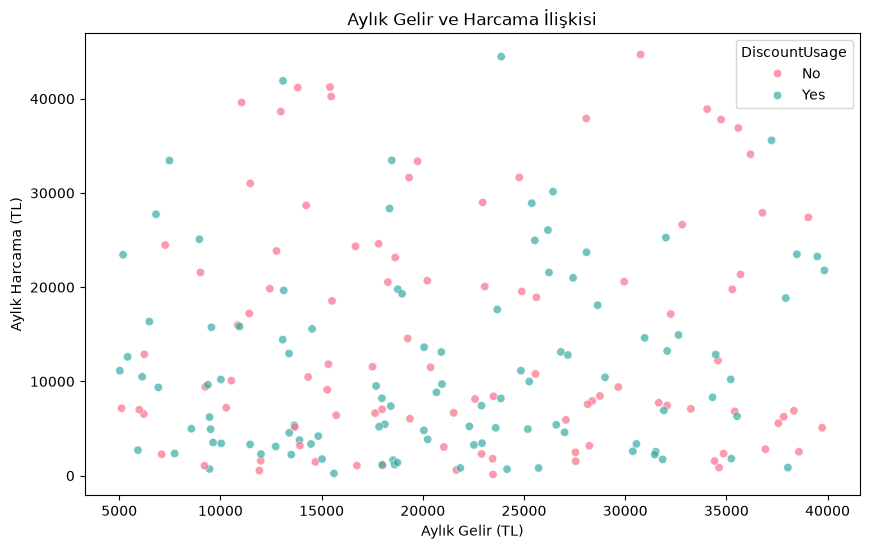

In [15]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='MonthlyIncome', y='MonthlySpending', hue='DiscountUsage', alpha=0.7, palette='husl')
plt.title("Aylık Gelir ve Harcama İlişkisi")
plt.xlabel("Aylık Gelir (TL)")
plt.ylabel("Aylık Harcama (TL)")

plt.show()

C:\Users\MyComputer\AppData\Local\Temp\ipykernel_23360\3390116137.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='CustomerSegment', palette='Set2')


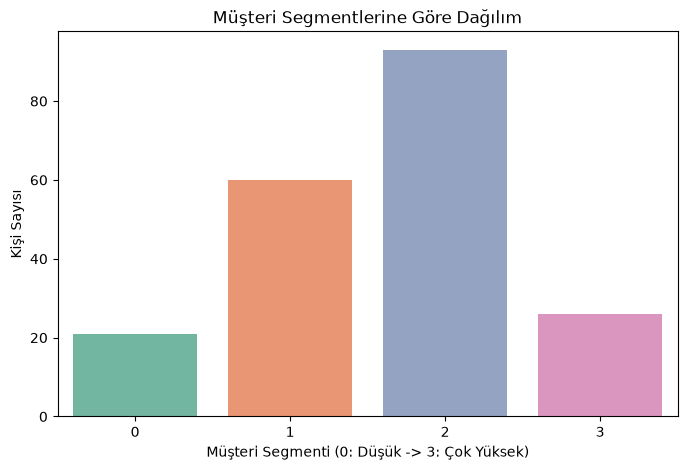

In [16]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='CustomerSegment', palette='Set2')
plt.title("Müşteri Segmentlerine Göre Dağılım")
plt.xlabel("Müşteri Segmenti (0: Düşük -> 3: Çok Yüksek)")
plt.ylabel("Kişi Sayısı")

plt.show()

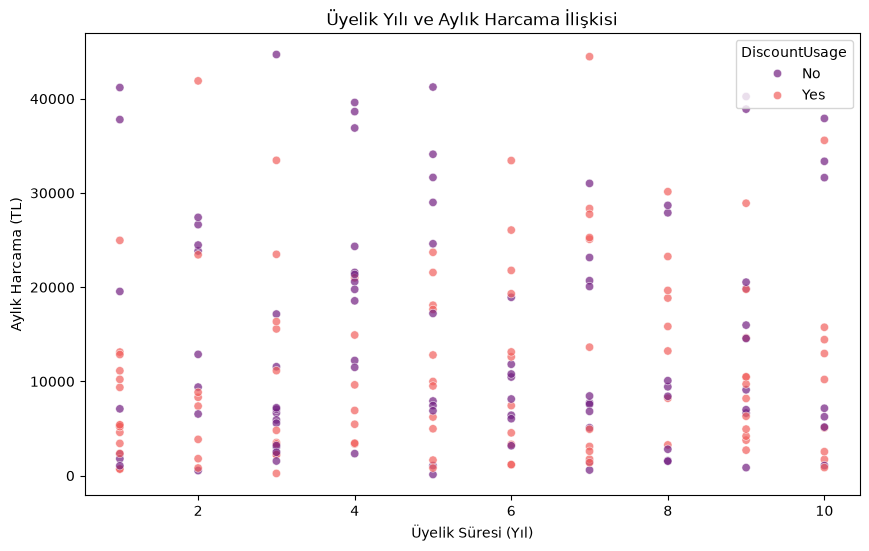

In [21]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='MembershipYears', y='MonthlySpending', hue='DiscountUsage', alpha=0.7, palette='magma')
plt.title("Üyelik Yılı ve Aylık Harcama İlişkisi")
plt.xlabel("Üyelik Süresi (Yıl)")
plt.ylabel("Aylık Harcama (TL)")

plt.show()

C:\Users\MyComputer\AppData\Local\Temp\ipykernel_23360\1600079038.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Gender', y='AverageBasket', palette='mako')


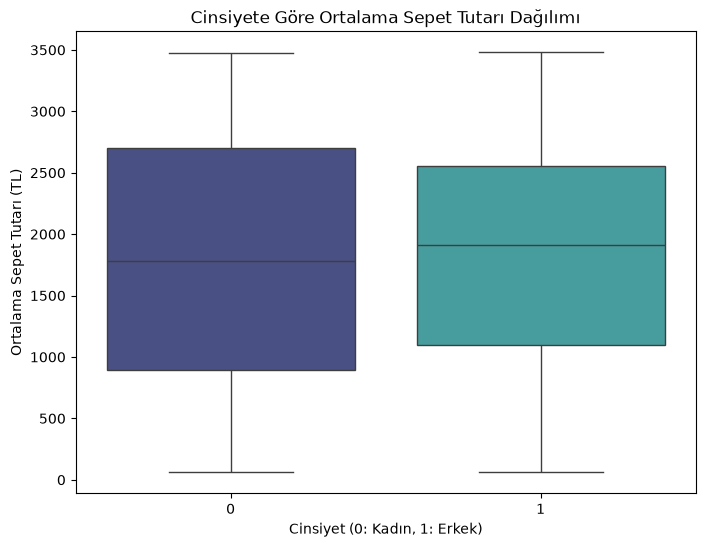

In [24]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='Gender', y='AverageBasket', palette='mako')
plt.title("Cinsiyete Göre Ortalama Sepet Tutarı Dağılımı")
plt.xlabel("Cinsiyet (0: Kadın, 1: Erkek)")
plt.ylabel("Ortalama Sepet Tutarı (TL)")

plt.show()